# Hotel Booking Data Analysis

**Course:** Data Processing with Python (HAMK)

**Group members:**
1. Anup Kandel
2. Sandesh Bishokarma
3. Sushant Koirala
4. Tanka Raj Aryal

**This notebook:** the part written by Sushant Koirala.

## Transformations and derived variables

Create at least these four derived variables:
- `arrival_date` — proper Pandas date;
- `total_nights` — weekend nights + weekday nights;
- `total_guests` — adults + children + babies;
- `estimated_booking_value` — average daily rate × total nights.

You may create additional useful variables if they support your research questions.

**Responsible:** Sushant Koirala.

In [1]:
# SETUP: makes this file run on its own.
# It repeats Tanka's load + cleaning.
# Anup deletes this cell when he merges everything into the shared notebook.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:.2f}".format)

# Chart settings from the lesson notebooks
plt.rcParams.update({
    "figure.figsize": (9, 5),
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

# File paths. This file is in notebooks/work/, so the data is two folders up.
# (In the shared notebook Anup changes '../../' to '../'.)
DATA_FILE = "../../data/hotel_bookings_final_project.csv"
CLEAN_FILE = "../../outputs/hotel_bookings_cleaned.csv"
SUMMARY_FILE = "../../outputs/hotel_booking_summary.csv"

hotel_raw = pd.read_csv(DATA_FILE)

hotel = hotel_raw.copy()   # cleaned copy, 'hotel_raw' stays untouched
rows_before = len(hotel)

# Missing country -> "Unknown" (country is not used in our questions)
hotel["country"] = hotel["country"].fillna("Unknown")

# Remove bookings with no guests at all (placeholder records)
hotel = hotel[(hotel["adults"] + hotel["children"] + hotel["babies"]) > 0].copy()

# Duplicates, long lead times and 0 EUR / high rates are kept (see cleaning log)

print("Bookings after cleaning:", len(hotel))

Bookings after cleaning: 997


In [2]:
hotel["arrival_date"] = pd.to_datetime(
    hotel["arrival_date_year"].astype(str) + "-" + hotel["arrival_date_month"] + "-"
    + hotel["arrival_date_day_of_month"].astype(str),
    format="%Y-%B-%d", errors="coerce")
hotel["total_nights"] = hotel["stays_in_weekend_nights"] + hotel["stays_in_week_nights"]
hotel["total_guests"] = hotel["adults"] + hotel["children"] + hotel["babies"]
hotel["estimated_booking_value"] = hotel["average_daily_rate"] * hotel["total_nights"]

# Optional extra variables that may help our questions
hotel["cancel_status"] = hotel["is_canceled"].map({0: "Not cancelled", 1: "Cancelled"})
hotel["arrival_month_num"] = hotel["arrival_date"].dt.month

hotel[["arrival_date", "total_nights", "total_guests", "average_daily_rate", "estimated_booking_value"]].head()

,arrival_date,total_nights,total_guests,average_daily_rate,estimated_booking_value
0,2015-09-30,2,1,98.10,196.20
1,2016-03-19,6,2,70.17,421.02
2,2017-08-01,4,2,193.40,773.60
3,2016-11-11,1,2,36.24,36.24
4,2017-07-27,2,2,89.10,178.20


In [3]:
# More helper columns, in the style of the lesson notebooks
hotel["booked_far_ahead"] = hotel["lead_time"] > 180          # True / False column
hotel["lead_time_band"] = pd.cut(
    hotel["lead_time"],
    bins=[-1, 7, 30, 90, 180, 365, float("inf")],
    labels=["0-7", "8-30", "31-90", "91-180", "181-365", "366+"],
)

print("Invalid arrival dates:", hotel["arrival_date"].isna().sum())
print("Bookings made more than 180 days ahead:", hotel["booked_far_ahead"].sum())
print(hotel["lead_time_band"].value_counts(sort=False))

Invalid arrival dates: 0
Bookings made more than 180 days ahead: 212
lead_time_band
0-7        143
8-30       170
31-90      252
91-180     220
181-365    184
366+        28
Name: count, dtype: int64


- `arrival_date` combines the three date columns into one real date (`datetime64`); 0 dates failed to convert.
- `total_nights` and `total_guests` add up their parts; `estimated_booking_value` = daily rate × nights (euros, before any cancellation).
- `cancel_status` turns 0/1 into readable labels, `arrival_month_num` (1–12) lets us sort months in calendar order.
- `booked_far_ahead` is a True/False flag and `lead_time_band` groups lead time with `pd.cut`, as in the bike-rentals lesson (`rental_level`).

## Individual-variable analysis

Analyze at least two categorical variables and two numerical variables.
- Categorical: counts; percentages; valid sample size (n); a suitable chart when useful (bar chart).
- Numerical: valid n; mean; median; standard deviation; minimum and maximum; a suitable visualization such as a histogram or box plot.

**Responsible:** Sushant Koirala.

In [4]:
def categorical_summary(df, column):
    """Counts and percentages for one categorical column, with the valid n."""
    counts = df[column].value_counts()
    table = pd.DataFrame({"count": counts, "percent": (counts / counts.sum() * 100).round(1)})
    print(f"{column}: valid n = {counts.sum()}")
    return table

def numerical_summary(df, columns):
    """Valid n, mean, median, std, min and max for numeric columns."""
    return df[columns].agg(["count", "mean", "median", "std", "min", "max"]).T.rename(columns={"count": "valid_n"})

hotel_table = categorical_summary(hotel, "hotel")
hotel_table

hotel: valid n = 997


,count,percent
hotel,,
City Hotel,639,64.10
Resort Hotel,358,35.90


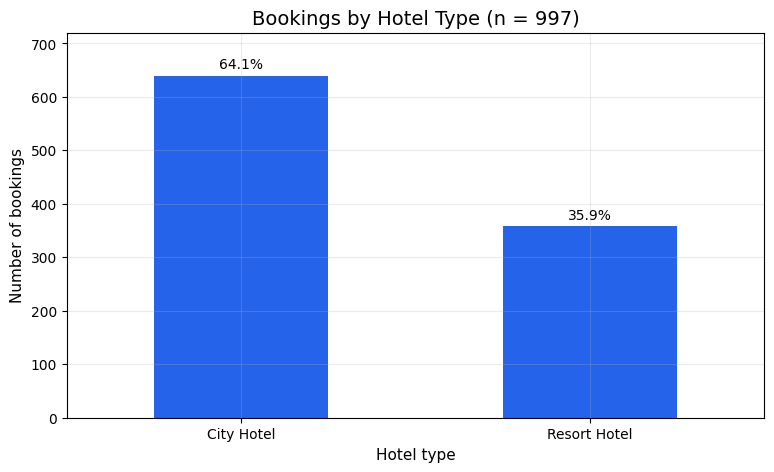

In [5]:
ax = hotel_table["count"].plot(kind="bar", color="#2563eb")
ax.bar_label(ax.containers[0], labels=[f"{p}%" for p in hotel_table["percent"]], padding=3)
ax.set_title(f"Bookings by Hotel Type (n = {hotel_table['count'].sum()})")
ax.set_xlabel("Hotel type")
ax.set_ylabel("Number of bookings")
ax.set_ylim(0, 720)
ax.tick_params(axis="x", rotation=0)
plt.show()

In [6]:
deposit_table = categorical_summary(hotel, "deposit_type")
deposit_table

deposit_type: valid n = 997


,count,percent
deposit_type,,
No Deposit,878,88.10
Non Refund,116,11.60
Refundable,3,0.30


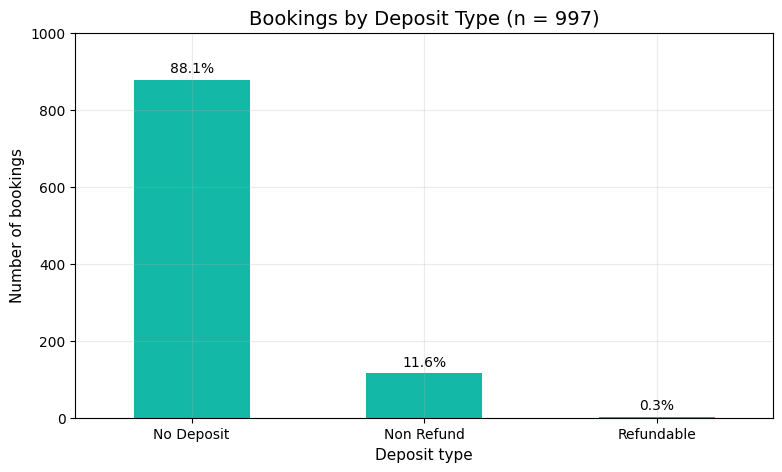

In [7]:
ax = deposit_table["count"].plot(kind="bar", color="#14b8a6")
ax.bar_label(ax.containers[0], labels=[f"{p}%" for p in deposit_table["percent"]], padding=3)
ax.set_title(f"Bookings by Deposit Type (n = {deposit_table['count'].sum()})")
ax.set_xlabel("Deposit type")
ax.set_ylabel("Number of bookings")
ax.set_ylim(0, 1000)
ax.tick_params(axis="x", rotation=0)
plt.show()

The City Hotel accounts for almost two thirds of the bookings (64.1 %). Most bookings need **no deposit** (88.1 %); *Non Refund* deposits are 11.6 % and *Refundable* deposits are very rare (0.3 %, n = 3).

In [8]:
numerical_summary(hotel, ["lead_time", "average_daily_rate", "total_nights"]).round(2)

,valid_n,mean,median,std,min,max
lead_time,997.00,105.32,71.00,106.49,0.00,542.00
average_daily_rate,997.00,101.52,94.50,45.45,0.00,304.00
total_nights,997.00,3.46,3.00,2.38,0.00,28.00


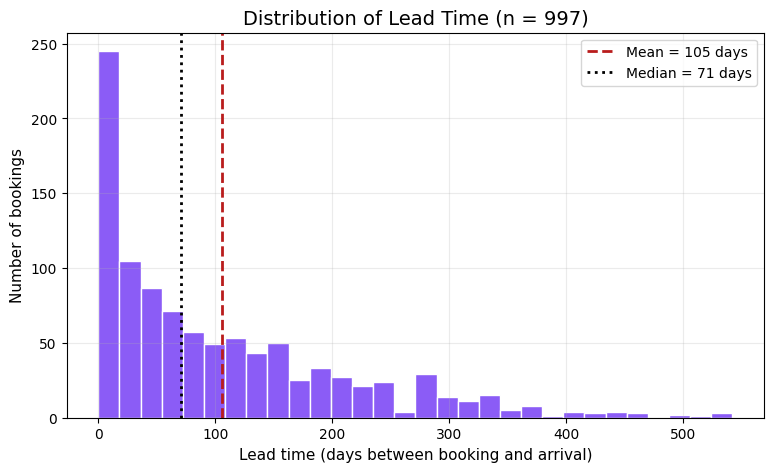

In [9]:
fig, ax = plt.subplots()
ax.hist(hotel["lead_time"], bins=30, color="#8b5cf6", edgecolor="white")
ax.axvline(np.mean(hotel["lead_time"]), color="#b91c1c", linestyle="--",
           linewidth=2, label=f"Mean = {np.mean(hotel['lead_time']):.0f} days")
ax.axvline(np.median(hotel["lead_time"]), color="black", linestyle=":",
           linewidth=2, label=f"Median = {np.median(hotel['lead_time']):.0f} days")
ax.set_title(f"Distribution of Lead Time (n = {hotel['lead_time'].notna().sum()})")
ax.set_xlabel("Lead time (days between booking and arrival)")
ax.set_ylabel("Number of bookings")
ax.legend()
plt.show()

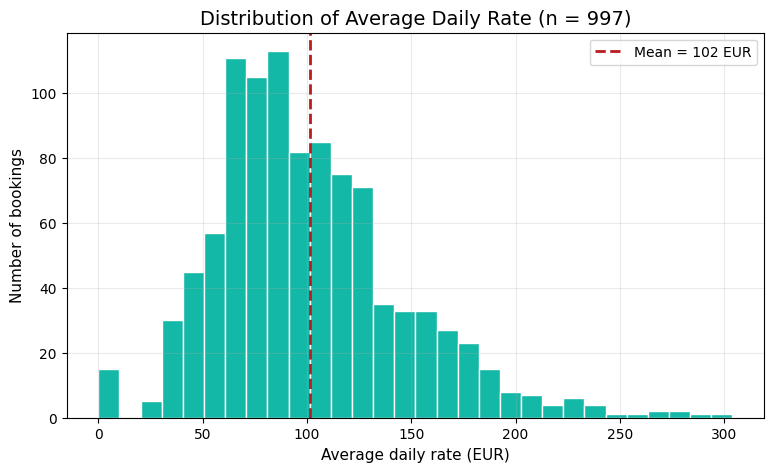

In [10]:
fig, ax = plt.subplots()
ax.hist(hotel["average_daily_rate"], bins=30, color="#14b8a6", edgecolor="white")
ax.axvline(np.mean(hotel["average_daily_rate"]), color="#b91c1c", linestyle="--",
           linewidth=2, label=f"Mean = {np.mean(hotel['average_daily_rate']):.0f} EUR")
ax.set_title(f"Distribution of Average Daily Rate (n = {hotel['average_daily_rate'].notna().sum()})")
ax.set_xlabel("Average daily rate (EUR)")
ax.set_ylabel("Number of bookings")
ax.legend()
plt.show()

**Lead time** is strongly right-skewed: most bookings are made within a few months of arrival (median 71 days), but a long tail reaches 542 days, which is why the mean (105 days) is far above the median.
**Average daily rate** is closer to symmetric around a median of about 95 €, with a small group of free (0 €) stays and a few high-season rates above 250 €.

## Final visualizations

At least four finished visualizations (Matplotlib or Pandas plotting): one categorical comparison; one numerical distribution;
one relationship or grouped comparison; one time-based or multi-group figure.

Each needs a descriptive title, clear axis labels, a legend when needed, readable labels, sensible formatting, and the sample size (n).
After each, write a short **What can we observe?** paragraph without unsupported causal claims.

**Responsible:** Sushant Koirala (Figure 2).

### Figure 2: numerical distribution (Sushant Koirala)

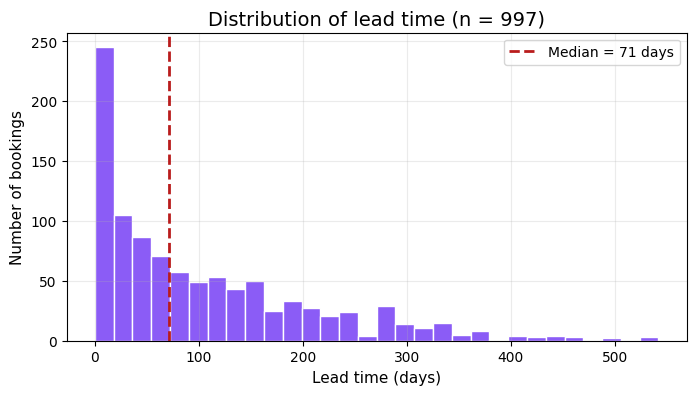

In [11]:
# Figure 2: numerical distribution - lead time
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(hotel["lead_time"], bins=30, color="#8b5cf6", edgecolor="white")
ax.axvline(hotel["lead_time"].median(), color="#b91c1c", linestyle="--",
           linewidth=2, label=f"Median = {hotel['lead_time'].median():.0f} days")
ax.set_title(f"Distribution of lead time (n = {hotel['lead_time'].notna().sum()})")
ax.set_xlabel("Lead time (days)")
ax.set_ylabel("Number of bookings")
ax.legend()
plt.show()

**What can we observe?** Most bookings are made less than about 100 days ahead, but there is a long right tail of bookings made up to 1.5 years in advance. Because of this skew, the median (71 days) describes a typical booking better than the mean (105 days).